In [1]:
from google.colab import files
uploaded = files.upload()

Saving Sales_data.xlsx to Sales_data (1).xlsx


In [2]:
import pandas as pd
df=pd.read_excel('Sales_data.xlsx')

In [3]:
df.head()

,transaction_id,customer_number,transaction_month,product_id,product_name,unit_price,volume_units,sales_amount,promo_offer
0,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01,P021,Dettol Antiseptic 250ml,305.70,10,3057.00,Yes
1,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01,P026,Kellogg's Corn Flakes 500g,405.20,5,2026.00,Yes
2,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01,P009,Lays Chips 200g,322.60,10,3226.00,Yes
3,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01,P037,Vim Dishwash Bar 200g,176.27,9,1586.43,Yes
4,a1e86962-46d7-4940-8759-b58c535b370b,75583263,2022-01,P026,Kellogg's Corn Flakes 500g,477.55,10,4775.50,No


In [4]:
df.describe()

,customer_number,unit_price,volume_units,sales_amount
count,8.295000e+04,82950.000000,82950.000000,82950.000000
mean,4.973458e+07,273.435430,5.497601,1503.266978
std,2.866339e+07,162.663667,2.873561,1280.993174
min,3.277000e+03,29.220000,1.000000,29.570000
25%,2.432787e+07,127.200000,3.000000,504.490000
50%,4.978368e+07,243.490000,5.000000,1095.100000
75%,7.489914e+07,378.760000,8.000000,2219.805000
max,9.996990e+07,582.850000,10.000000,5828.500000


In [5]:
df.isnull().sum()

,0
transaction_id,0
customer_number,0
transaction_month,0
product_id,0
product_name,0
unit_price,0
volume_units,0
sales_amount,0
promo_offer,0


In [6]:
df.drop_duplicates(inplace=True)

In [7]:
df.shape

(82950, 9)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82950 entries, 0 to 82949
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   transaction_id     82950 non-null  object 
 1   customer_number    82950 non-null  int64  
 2   transaction_month  82950 non-null  object 
 3   product_id         82950 non-null  object 
 4   product_name       82950 non-null  object 
 5   unit_price         82950 non-null  float64
 6   volume_units       82950 non-null  int64  
 7   sales_amount       82950 non-null  float64
 8   promo_offer        82950 non-null  object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.7+ MB


In [9]:
df['transaction_month']=pd.to_datetime(df['transaction_month'])

In [10]:
df.head()

,transaction_id,customer_number,transaction_month,product_id,product_name,unit_price,volume_units,sales_amount,promo_offer
0,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01-01,P021,Dettol Antiseptic 250ml,305.70,10,3057.00,Yes
1,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01-01,P026,Kellogg's Corn Flakes 500g,405.20,5,2026.00,Yes
2,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01-01,P009,Lays Chips 200g,322.60,10,3226.00,Yes
3,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01-01,P037,Vim Dishwash Bar 200g,176.27,9,1586.43,Yes
4,a1e86962-46d7-4940-8759-b58c535b370b,75583263,2022-01-01,P026,Kellogg's Corn Flakes 500g,477.55,10,4775.50,No


In [11]:
df['Year'] = df['transaction_month'].dt.year

df['Month'] = df['transaction_month'].dt.month

In [12]:
df.head()

,transaction_id,customer_number,transaction_month,product_id,product_name,unit_price,volume_units,sales_amount,promo_offer,Year,Month
0,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01-01,P021,Dettol Antiseptic 250ml,305.70,10,3057.00,Yes,2022,1
1,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01-01,P026,Kellogg's Corn Flakes 500g,405.20,5,2026.00,Yes,2022,1
2,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01-01,P009,Lays Chips 200g,322.60,10,3226.00,Yes,2022,1
3,6ae6b99d-9158-43f2-ac7e-52f17620fc40,75583263,2022-01-01,P037,Vim Dishwash Bar 200g,176.27,9,1586.43,Yes,2022,1
4,a1e86962-46d7-4940-8759-b58c535b370b,75583263,2022-01-01,P026,Kellogg's Corn Flakes 500g,477.55,10,4775.50,No,2022,1


In [13]:
#Top Selling Products
top_products=df.groupby('product_name')['sales_amount'].sum()
top_products.sort_values(ascending=False).head(10)

,sales_amount
product_name,
Godrej Shampoo 200ml,6291047.29
Milky Mist Paneer 200g,6278408.60
Santoor Soap 75g,6029465.11
Pepsodent Combo Pack,5902345.04
Dove Soap 75g,5534074.21
Red Label Tea 250g,5374852.36
Palmolive Shampoo 180ml,5312118.65
Kellogg's Corn Flakes 500g,5098624.12
Amul Butter 100g,4783230.37


In [14]:
df.groupby('product_name')['volume_units'] \
  .sum() \
  .sort_values(ascending=False) \
  .head(10)

,volume_units
product_name,
Cinthol Soap 100g,11584
Patanjali Aloe Vera Gel 100ml,11563
Amul Butter 100g,11459
Tata Salt 1kg,11446
Surf Excel Detergent 1kg,11438
Dove Soap 75g,11412
Pepsi Cola 2L Bottle,11386
Amul Cheese Slice 400g,11384
Cadbury Dairy Milk 50g,11380


In [15]:
monthly_sales=df.groupby('transaction_month')['sales_amount'].sum()
print(monthly_sales)

transaction_month
2022-01-01    1641784.46
2022-02-01    3006115.15
2022-03-01    4214472.09
2022-04-01    5287652.14
2022-05-01    5536292.74
2022-06-01    5840271.84
2022-07-01    5842066.12
2022-08-01    6165023.84
2022-09-01    6191852.10
2022-10-01    6028041.60
2022-11-01    5855565.39
2022-12-01    6261031.43
2023-01-01    6304850.32
2023-02-01    5954485.11
2023-03-01    6481715.86
2023-04-01    6035719.68
2023-05-01    6335254.62
2023-06-01    6011657.79
2023-07-01    6063637.37
2023-08-01    5698299.69
2023-09-01    5131903.82
2023-10-01    4030371.81
2023-11-01    3052154.21
2023-12-01    1725776.65
Name: sales_amount, dtype: float64


In [16]:

promo_sales = df.groupby('promo_offer')['sales_amount'].sum()

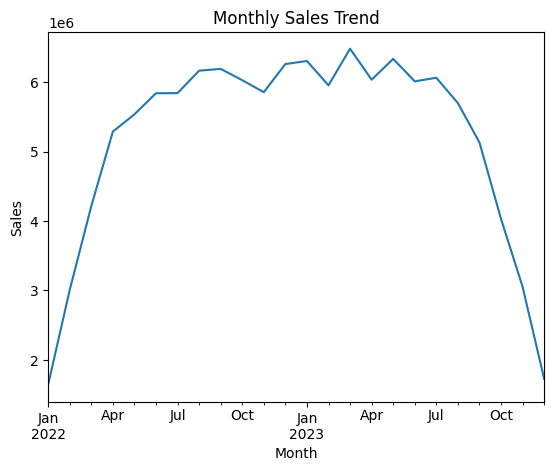

In [17]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind='line')

plt.title("Monthly Sales Trend")

plt.xlabel("Month")

plt.ylabel("Sales")

plt.show()

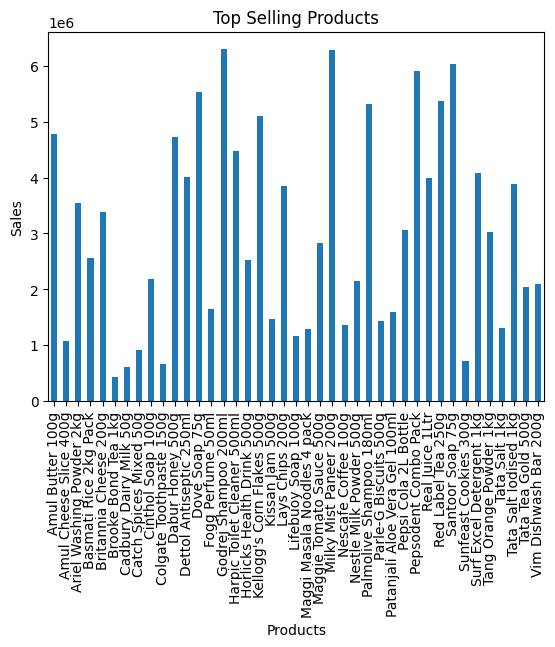

In [18]:
top_products.plot(kind='bar')

plt.title("Top Selling Products")

plt.xlabel("Products")

plt.ylabel("Sales")

plt.show()

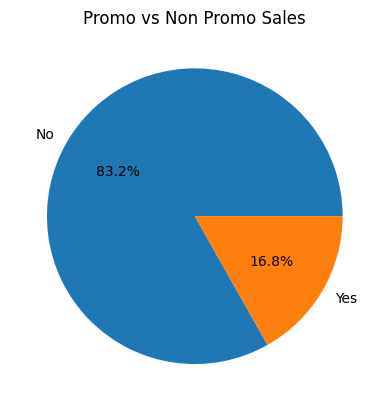

In [19]:

promo_sales.plot(kind='pie', autopct='%1.1f%%')

plt.title("Promo vs Non Promo Sales")

plt.ylabel("")

plt.show()

In [20]:
df.groupby('promo_offer')['sales_amount'].sum()

,sales_amount
promo_offer,
No,1.037290e+08
Yes,2.096696e+07


In [21]:
df['sales_amount'].sum()

np.float64(124695995.83)

In [22]:
df.groupby('product_name')['sales_amount'] \
  .sum() \
  .idxmax()

'Godrej Shampoo 200ml'

In [23]:
import sqlite3

conn = sqlite3.connect("retail_sales.db")

df.to_sql("sales", conn, if_exists="replace", index=False)

82950

In [24]:
query = """
SELECT product_name,
SUM(sales_amount) as total_sales
FROM sales
GROUP BY product_name
ORDER BY total_sales DESC
LIMIT 5
"""

result = pd.read_sql(query, conn)

print(result)

             product_name  total_sales
0    Godrej Shampoo 200ml   6291047.29
1  Milky Mist Paneer 200g   6278408.60
2        Santoor Soap 75g   6029465.11
3    Pepsodent Combo Pack   5902345.04
4           Dove Soap 75g   5534074.21


In [25]:
def chatbot(query):

    query = query.lower()

    if "top products" in query:

        return df.groupby('product_name')['sales_amount'] \
                 .sum() \
                 .sort_values(ascending=False) \
                 .head(5)

    elif "monthly sales" in query:

        return df.groupby('transaction_month')['sales_amount'].sum()

    elif "promo sales" in query:

        return df.groupby('promo_offer')['sales_amount'].sum()

    else:

        return "Query not understood"

In [26]:
chatbot("top products")

,sales_amount
product_name,
Godrej Shampoo 200ml,6291047.29
Milky Mist Paneer 200g,6278408.60
Santoor Soap 75g,6029465.11
Pepsodent Combo Pack,5902345.04
Dove Soap 75g,5534074.21


In [27]:
chatbot("promo sales")

,sales_amount
promo_offer,
No,1.037290e+08
Yes,2.096696e+07


In [28]:
chatbot("month")

'Query not understood'

In [29]:
best_product = df.groupby('product_name')['sales_amount'] \
                 .sum() \
                 .idxmax()

print(f"{best_product} generated the highest revenue.")

Godrej Shampoo 200ml generated the highest revenue.


In [30]:
suggestions = [
    "Top products",
    "Monthly sales",
    "Promo impact",
    "Best product",
    "Most sold products"
]

print("\nSuggested Questions:")

for s in suggestions:

    print("-", s)


Suggested Questions:
- Top products
- Monthly sales
- Promo impact
- Best product
- Most sold products


In [31]:
pip install flask pandas openpyxl

In [32]:
!pip install pyngrok

In [33]:
from pyngrok import ngrok

ngrok.set_auth_token("3E1VNVoOW69jgNxsn3r0ZGemC33_8VLLwEUkfpJQ5G1TGPsA")

In [34]:
from flask import Flask, request, jsonify
import pandas as pd
import time
from datetime import datetime

app = Flask(__name__)

df = pd.read_excel("Sales_data.xlsx")

@app.route('/')
def home():
    return "Retail Analytics Chatbot Running!"

@app.route('/chat', methods=['POST'])
def chat():
    start_time = time.time()

    user_query = request.json['query'].lower()

    if "top products" in user_query:

        answer = (
            df.groupby('product_name')['sales_amount']
            .sum()
            .sort_values(ascending=False)
            .head(5)
            .to_dict()
        )

    elif "total sales" in user_query:

        answer = float(df['sales_amount'].sum())

    elif "promo impact" in user_query:

        answer = (
            df.groupby('promo_offer')['sales_amount']
            .sum()
            .to_dict()
        )

    elif "best product" in user_query:

        answer = (
            df.groupby('product_name')['sales_amount']
            .sum()
            .idxmax()
        )

    else:

        answer = "Query not understood"

    response_time = round(time.time() - start_time, 2)

    return jsonify({
        "answer": answer,
        "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "response_time": response_time
    })

from pyngrok import ngrok
import threading

def run():
    app.run(port=5000)

threading.Thread(target=run).start()

public_url = ngrok.connect(5000)
print("Public URL:", public_url)

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit


Public URL: NgrokTunnel: "https://dreaded-vicinity-babble.ngrok-free.dev" -> "http://localhost:5000"
